# Lab 9, Part 4 without a Google Cloud bill

Lab 9 asks for three demos: **a BigQuery query, a Looker Studio chart and an OCR result**. This
notebook does all three, plus document parsing and a prompt, without a Google Cloud account, a
credit card, an API key or the 300-dollar trial. Everything runs inside this Colab:

| Demo | Instead of | What runs here |
|---|---|---|
| **1. A SQL query over a public dataset** | BigQuery | DuckDB reads a public Parquet file over HTTPS |
| **2. A public dashboard over a public dataset** | (Looker Studio itself: it is free and needs only a Google account) | you build it by hand |
| **3. OCR** | Vision API | Tesseract and EasyOCR |
| **4. Document parsing** | Document AI | Qwen3-VL 2B, an open vision-language model, through Ollama |
| **5. Your prompt: an LLM as a form parser** | Document AI Form Parser | the same model, with a JSON schema |

**How you work:** run the cells from top to bottom. The only cell you must edit is `MY_PROMPT` in
section 5. When you are done, *Runtime → Run all* must finish without errors: **you submit the link
to this notebook with its outputs**. The last section, *What you submit (in case no GCP account)*,
lists everything to hand in for the whole lab on this route.

## How long it takes

No GPU is needed: everything runs on the free CPU runtime. A GPU only makes sections 4 and 5
faster. Measured on Colab on 18 November 2026:

| | Free CPU runtime | Free T4 GPU runtime |
|---|---|---|
| Whole notebook, first run | **~11 min** | **~4 min** |
| Section 4: the page to Markdown | ~5 min (314 s) | ~30 s (28 s) |
| Section 5: one answer (A or B) | ~1.5–2 min (103 s / 99 s) | ~2–3 s |
| Fields right, Qwen3-VL 2B | 8 of 9 for A and B | 8 of 9 for A and B |

The result is the same on CPU and GPU; only the time differs. While you edit your prompt in
section 5, each rerun costs about **3.5 minutes on CPU** (two answers) and a few seconds on a T4.

- The first run also downloads the models: EasyOCR ~0.1 GB, Qwen3-VL 2B ~1.9 GB.
- To try a GPU: *Runtime → Change runtime type → T4 GPU*. The free tier gives a T4 only when one is
  free. If Colab says *"Cannot connect to GPU backend"*, close your other sessions (*Runtime →
  Manage sessions*) and try later, or stay on CPU: the result is the same.
- On CPU, start the run and do something else; do not close the tab. If the session crashes with
  *"used all available RAM"*, run the notebook again from the top: the notebook frees the OCR
  models before it loads the LLM, and that only works when the cells run in order.

## 1. A SQL query over a public dataset: DuckDB instead of BigQuery

BigQuery needs a Google Cloud project. DuckDB is an embedded SQL engine that runs inside Colab. It reads a Parquet file over HTTPS and, like BigQuery, fetches
only the columns and row groups the query needs. The file is the January 2024 NYC yellow-taxi
data (~3 million trips, ~50 MB) published by the NYC Taxi & Limousine Commission.

In [ ]:
%pip install -q duckdb
import duckdb

con = duckdb.connect()
con.sql("INSTALL httpfs; LOAD httpfs;")
URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"

taxi_by_hour = con.sql(f'''
    SELECT hour(tpep_pickup_datetime) AS hour,
           count(*)                   AS trips,
           round(avg(fare_amount), 2) AS avg_fare
    FROM read_parquet('{URL}')
    GROUP BY hour
    ORDER BY hour
''').df()
taxi_by_hour   # 📸 screenshot this table

,hour,trips,avg_fare
0,0,79094,19.20
1,1,53627,17.53
2,2,37517,16.48
3,3,24811,18.15
4,4,16742,22.52
5,5,18764,26.62
6,6,41429,21.65
7,7,83719,18.54
8,8,117209,17.65
9,9,128970,17.71


What is the same and what is not: the SQL and the column-store idea are the same. What BigQuery
adds is that the data is already there (hundreds of public datasets), the engine is someone
else's cluster, and the price is per byte scanned instead of your laptop's time.

## 2. A public Looker Studio dashboard (only a Google account)

Looker Studio is free with any Google account; it is not part of a Cloud project and needs no
billing. Here you build a dashboard over a public dataset and publish it.

**The dataset:** *CO₂ and Greenhouse Gas Emissions* by Our World in Data, one CSV (~15 MB): one row
per country and year from 1750 to 2025. Columns you will need:

| Column | What it is |
|---|---|
| `country`, `iso_code` | Country name and ISO code. Rows such as *World* or *Europe* are aggregates and have **no** `iso_code` |
| `year` | Year |
| `population`, `gdp` | Population, GDP |
| `co2` | Annual CO₂ emissions, million tonnes |
| `co2_per_capita` | Tonnes of CO₂ per person |
| `coal_co2`, `oil_co2`, `gas_co2` | CO₂ by fuel, million tonnes |

Download: https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv
(the codebook with every column: https://github.com/owid/co2-data).

**Build the dashboard (~20 min):**

1. Download the CSV to your laptop.
2. Open https://lookerstudio.google.com → **Blank report** → **Add data → File upload** → upload
   the CSV. Check the field types: `year` and the numeric columns must be *Number*, `country` *Text*,
   `iso_code` *Country ISO code* (Geo) for the map.
3. Add at least these four elements:
   - a **line chart**: `co2` by `year` for Ukraine and two countries of your choice (filter on `country`);
   - a **geo chart**: `co2_per_capita` by `iso_code` for `year = 2025`;
   - a **bar chart**: the top 10 countries by `co2` in 2025, without aggregates (filter: `iso_code` is not null);
   - a **control**: a drop-down list on `country` or a slider / range on `year`, which changes the charts.
4. Give the report a title and put your name on it.
5. **Publish it: Share → Manage access → "Anyone with the link can view"** (or *Public*), then copy
   the link. Open it in a private window to check that it works without signing in. If your UCU
   account does not allow links outside the university, make the report with a personal Google
   account.

**Submit the link to the public dashboard**, plus one sentence: what is one thing you noticed in
the data?

## 3. OCR without Vision API or Document AI

Vision API and Document AI are managed OCR services. The same task runs on open-source models
inside Colab:

| Library | What it is | Good at | Weak at |
|---|---|---|---|
| **Tesseract** (`pytesseract`) | Classic OCR engine (Google's, open source), CPU, 100+ languages incl. Ukrainian | Clean printed text, scans, fast | Photos at an angle, handwriting, complex layouts |
| **EasyOCR** | Deep-learning detector + recogniser, CPU or GPU, 80+ languages incl. Ukrainian | Photos, receipts, signs, text at an angle | Handwriting, long documents (slow on CPU) |
| **docTR** (Mindee) | Detection + recognition models with page layout | Documents and PDFs, words with positions | Cyrillic is weaker than Latin |
| **PaddleOCR** | Large model zoo, tables and layout (PP-Structure) | Tables, layout, many languages | Heavier install |
| **TrOCR** (Hugging Face) | Transformer for **one line** of text, has a handwritten model | Handwritten lines (English) | Whole pages: you must cut lines first |

What a managed service adds: no install, a model trained on far more data, handwriting, form and
table parsing (Document AI's Form Parser), and an SLA. What it costs: money per page and sending
your documents to someone else's cloud.

### 3.1 An image to read

The cell draws a small test receipt so the notebook works on its own. To use **your own photo**
(a receipt or a handwritten page, which is what Lab 9 asks for), run the cell after it and upload a
file.

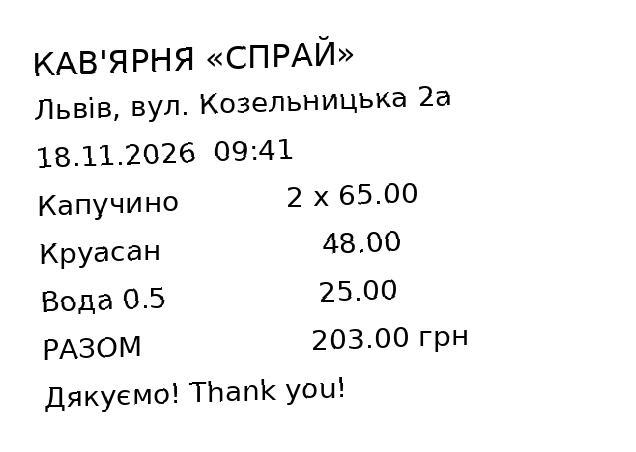

In [ ]:
from PIL import Image, ImageDraw, ImageFont
import os

def font(size):
    # DejaVu Sans ships with matplotlib, so it is there on any Colab runtime (and it has Cyrillic).
    from matplotlib import font_manager
    return ImageFont.truetype(font_manager.findfont("DejaVu Sans"), size)

lines = ["КАВ'ЯРНЯ «СПРАЙ»", "Львів, вул. Козельницька 2а", "18.11.2026  09:41",
         "Капучино            2 x 65.00", "Круасан                  48.00",
         "Вода 0.5                 25.00", "РАЗОМ                   203.00 грн",
         "Дякуємо! Thank you!"]
img = Image.new("RGB", (620, 430), "white")
d = ImageDraw.Draw(img)
for i, line in enumerate(lines):
    d.text((30, 25 + i * 48), line, fill="black", font=font(28 if i else 32))
img = img.rotate(2, expand=True, fillcolor="white")   # a slight tilt, as in a real photo
img.save("receipt.png")
IMAGE_PATH = "receipt.png"
img

In [ ]:
# Optional: use your own photo or scan instead of the test receipt.
UPLOAD_MY_OWN = False  # @param {type:"boolean"}
if UPLOAD_MY_OWN:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        IMAGE_PATH = next(iter(uploaded))
print("Using", IMAGE_PATH)

Using receipt.png


### 3.2 Tesseract

In [ ]:
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ukr > /dev/null
%pip install -q pytesseract
import pytesseract
from PIL import Image

text = pytesseract.image_to_string(Image.open(IMAGE_PATH), lang="ukr+eng")
print(text)

КАВ'ЯРНЯ «СПРАЙ»
Львів, вул. Козельницька 2a
18.11.2026 09:41

Капучино 2 х 65.00
Круасан 48.00
Вода 0.5 25.00
РАЗОМ 203.00 грн

Дякуємо! Thank you!



23 words, mean confidence 95%


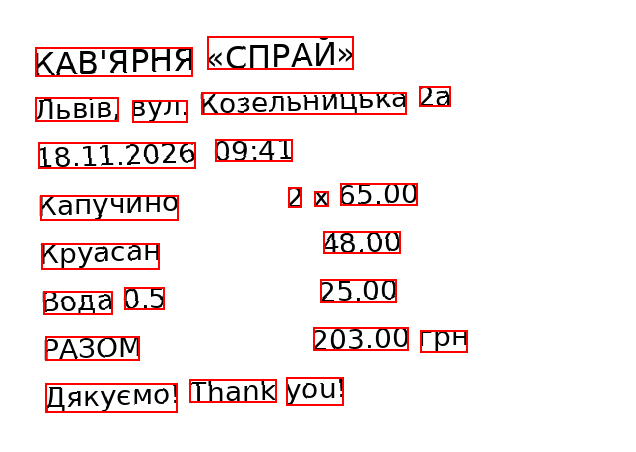

In [ ]:
# Words with positions and confidence: the same shape of answer Vision API returns.
from PIL import ImageDraw
data = pytesseract.image_to_data(Image.open(IMAGE_PATH), lang="ukr+eng",
                                 output_type=pytesseract.Output.DATAFRAME)
words = data[(data.conf > 0) & data.text.notna() & (data.text.str.strip() != "")]
boxed = Image.open(IMAGE_PATH).convert("RGB")
d = ImageDraw.Draw(boxed)
for _, w in words.iterrows():
    d.rectangle([w.left, w.top, w.left + w.width, w.top + w.height], outline="red", width=2)
print(f"{len(words)} words, mean confidence {words.conf.mean():.0f}%")
boxed   # 📸 screenshot the boxes and the text above

### 3.3 EasyOCR

The first run downloads the models (~100 MB). It uses the GPU if the runtime has one; CPU is fine
for one image.

In [ ]:
%pip install -q easyocr
import easyocr, torch
reader = easyocr.Reader(["uk", "en"], gpu=torch.cuda.is_available())   # Ukrainian + English
results = reader.readtext(IMAGE_PATH)          # [(box, text, confidence), ...]
for box, text, conf in results:
    print(f"{conf:.2f}  {text}")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.1% Complete0.67  КАВ'ЯРНЯ <СПРАЙ>
0.99  Львів;
1.00  вул
0.80  Козельницька 2a
0.82  18.11.2026
0.90  09:41
0.77  2 x 65.00
1.00  Капучино
1.00  48.00
1.00  Круасан
0.93  Вода 0.5
0.99  25.00
1.00  РАЗОМ
1.00  203.00 грн
0.92  Дякуємо! Thank you!


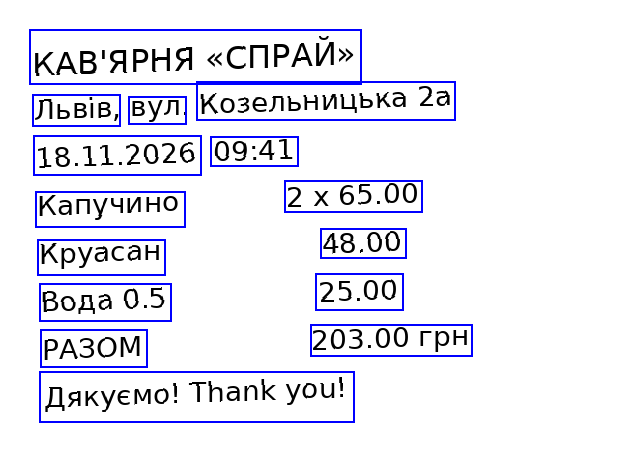

In [ ]:
from PIL import Image, ImageDraw
boxed = Image.open(IMAGE_PATH).convert("RGB")
d = ImageDraw.Draw(boxed)
for box, text, conf in results:
    d.polygon([tuple(map(int, p)) for p in box], outline="blue", width=2)
boxed   # 📸 compare with Tesseract

### 3.4 Handwriting

Neither Tesseract nor EasyOCR reads handwriting well; that is exactly where Vision API and
Document AI earn their price. A free way to try it: **TrOCR** (`microsoft/trocr-base-handwritten`
on Hugging Face) reads **one line** of English handwriting; crop a line and pass it to
`TrOCRProcessor` + `VisionEncoderDecoderModel`. Section 5 tries a multimodal LLM instead.

## 4. Document AI, open source: a small vision-language model

OCR returns lines of text. **Document AI** returns a *document*: headings, key–value pairs and
tables in reading order. The open-source counterparts:

| Model or library | What it does |
|---|---|
| **A small vision-language model** (Qwen3-VL 2B, Apache 2.0) | Reads the page image and writes it out as Markdown. One general model, also used for section 5. **Used here** |
| **PaddleOCR-VL**, **GLM-OCR**, **LightOnOCR** | ~1B models trained only for documents: better on dense pages and tables, but one more model to install |
| **Docling** (IBM), **MinerU**, **Marker** | Pipelines: layout model + OCR + table model → Markdown and JSON |
| **Unstructured** | Splits documents into typed elements (title, table, list) for RAG pipelines |

We run it on a scanned **invoice**. The notebook draws the invoice itself, so the right answer is
known and section 5 can check your result against it. The model runs inside this Colab through
**Ollama**, 4-bit quantised, on the CPU or on the GPU if there is one.

Ground truth (what a perfect parser returns):
{
  "invoice_number": "INV-2026-0417",
  "date": "2026-11-12",
  "due_date": "2026-11-26",
  "seller": "Spry Analytics LLC, 2a Kozelnytska St, Lviv",
  "buyer": "Ukrainian Catholic University, 17 Sventsitskoho St, Lviv",
  "items": [
    {
      "description": "Meeting analytics, Team plan (monthly)",
      "qty": 1,
      "unit_price": 120.0
    },
    {
      "description": "Extra seats",
      "qty": 15,
      "unit_price": 4.5
    },
    {
      "description": "Onboarding workshop (2 h)",
      "qty": 1,
      "unit_price": 200.0
    }
  ],
  "vat_rate": 0.2,
  "subtotal": 387.5,
  "vat": 77.5,
  "total": 465.0
}


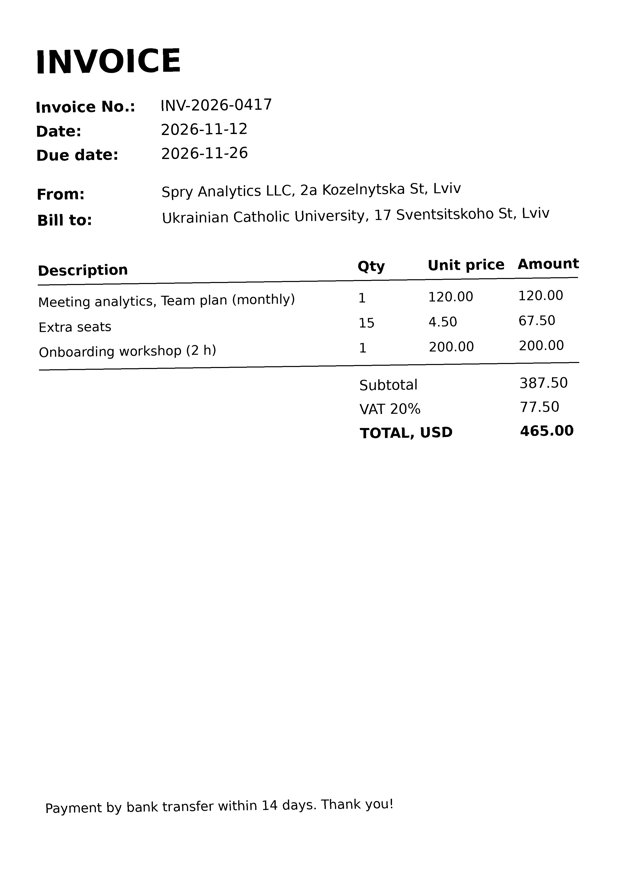

In [ ]:
# Test document 1: a scanned invoice. We draw it, so we know the right answer.
from PIL import Image, ImageDraw, ImageFont
import os, json

def font(size, bold=False):
    # DejaVu Sans ships with matplotlib, so it is there on any Colab runtime (and it has Cyrillic).
    from matplotlib import font_manager
    path = font_manager.findfont(font_manager.FontProperties(family="DejaVu Sans", weight="bold" if bold else "normal"))
    return ImageFont.truetype(path, size)

INVOICE = {
    "invoice_number": "INV-2026-0417",
    "date": "2026-11-12",
    "due_date": "2026-11-26",
    "seller": "Spry Analytics LLC, 2a Kozelnytska St, Lviv",
    "buyer": "Ukrainian Catholic University, 17 Sventsitskoho St, Lviv",
    "items": [
        {"description": "Meeting analytics, Team plan (monthly)", "qty": 1, "unit_price": 120.00},
        {"description": "Extra seats", "qty": 15, "unit_price": 4.50},
        {"description": "Onboarding workshop (2 h)", "qty": 1, "unit_price": 200.00},
    ],
    "vat_rate": 0.20,
}
subtotal = sum(i["qty"] * i["unit_price"] for i in INVOICE["items"])
vat = round(subtotal * INVOICE["vat_rate"], 2)
INVOICE.update(subtotal=subtotal, vat=vat, total=round(subtotal + vat, 2))

W, H = 2480, 3508                      # A4 at 150 dpi
page = Image.new("RGB", (W, H), "white")
d = ImageDraw.Draw(page)
d.text((160, 160), "INVOICE", font=font(128, True), fill="black")
y = 380
for label, key in [("Invoice No.", "invoice_number"), ("Date", "date"), ("Due date", "due_date")]:
    d.text((160, y), f"{label}:", font=font(60, True), fill="black")
    d.text((660, y), INVOICE[key], font=font(60), fill="black"); y += 96
y += 60
for label, key in [("From", "seller"), ("Bill to", "buyer")]:
    d.text((160, y), f"{label}:", font=font(60, True), fill="black")
    d.text((660, y), INVOICE[key], font=font(56), fill="black"); y += 104
y += 100
cols = [160, 1440, 1720, 2080]
for x, h in zip(cols, ["Description", "Qty", "Unit price", "Amount"]):
    d.text((x, y), h, font=font(56, True), fill="black")
d.line([(160, y + 88), (W - 160, y + 88)], fill="black", width=4); y += 128
for it in INVOICE["items"]:
    row = [it["description"], str(it["qty"]), f'{it["unit_price"]:.2f}', f'{it["qty"] * it["unit_price"]:.2f}']
    for x, v in zip(cols, row):
        d.text((x, y), v, font=font(52), fill="black")
    y += 100
d.line([(160, y), (W - 160, y)], fill="black", width=4); y += 48
for label, v in [("Subtotal", INVOICE["subtotal"]), ("VAT 20%", INVOICE["vat"]), ("TOTAL, USD", INVOICE["total"])]:
    d.text((1440, y), label, font=font(56, label.startswith("TOTAL")), fill="black")
    d.text((2080, y), f"{v:.2f}", font=font(56, label.startswith("TOTAL")), fill="black"); y += 96
d.text((160, H - 320), "Payment by bank transfer within 14 days. Thank you!", font=font(52), fill="black")

scan = page.rotate(0.8, expand=False, fillcolor="white")   # a scanner never feeds it straight
scan.save("invoice.pdf", resolution=300)
scan.save("invoice.png")
print("Ground truth (what a perfect parser returns):")
print(json.dumps(INVOICE, indent=2))
scan.resize((620, 877))

In [ ]:
# Free the RAM held by EasyOCR before the model starts: the free runtime has ~12.7 GB.
import gc, subprocess, time, urllib.request, torch
globals().pop("reader", None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
HARDWARE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

# Ollama runs open models locally; it uses the GPU if the runtime has one.
!apt-get -qq install -y zstd > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(60):
    try:
        urllib.request.urlopen("http://127.0.0.1:11434"); break
    except Exception:
        time.sleep(1)

MODEL = "qwen3-vl:2b-instruct"          # 1.9 GB, text + images, Apache 2.0
pulled = subprocess.run(["ollama", "pull", MODEL], capture_output=True, text=True)
assert pulled.returncode == 0, pulled.stderr[-500:]
%pip install -q ollama
import ollama

SYSTEM = {"role": "system", "content": "You are a precise assistant. Any text you write that is not "
          "English must be in Ukrainian, never in Russian. Copy text from documents exactly as written."}

def ask(prompt, image=None, schema=None, max_tokens=1024):
    """One question to the model: text, optionally an image, optionally a JSON schema for the answer."""
    message = {"role": "user", "content": prompt}
    if image:
        message["images"] = [image]
    reply = ollama.chat(model=MODEL, messages=[SYSTEM, message], format=schema,
                        options={"temperature": 0, "num_ctx": 4096, "num_predict": max_tokens})
    return reply["message"]["content"]

# Small models drift into Russian when asked for Ukrainian; the system message forbids it,
# and this check warns if the model still answers in Russian.
t = time.time()
hello = ask('Translate into Ukrainian: "Good morning, students!" Output only the translation.')
print(hello)
print(f"First answer, with the model loading: {time.time() - t:.0f} s on {HARDWARE}")
if set("ыэъё") & set(hello.lower()):
    print("WARNING: the model answered in Russian; check the Ukrainian text in its answers below")
!ollama ps        # the PROCESSOR column shows whether the model sits on the GPU or the CPU

Добрий ранок, студенти!
First answer, with the model loading: 105 s on Tesla T4
NAME                    ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3-vl:2b-instruct    afc393e3572c    2.0 GB    100% GPU     4096       llamacpp    4 minutes from now    


The next cell gives the model the page image and asks for Markdown: that is the "document parser"
step. Compare the result with the image: are the labels next to their values, and is the items
table a table?

In [ ]:
# A smaller copy of the scan: still readable, but far fewer image tokens, which matters on CPU.
Image.open("invoice.png").resize((868, 1228)).save("invoice_small.png")

TO_MARKDOWN = """Convert this page to Markdown.
- Keep every label on the same line as its value.
- Write tables as Markdown tables.
- Copy the text exactly; add nothing and explain nothing.
Output only the Markdown."""

t = time.time()
invoice_md = ask(TO_MARKDOWN, image="invoice_small.png")
t_page = time.time() - t
print(invoice_md)
print(f"\nPage to Markdown on {HARDWARE}: {t_page:.0f} s")

```markdown
# INVOICE

**Invoice No.:** INV-2026-0417
**Date:** 2026-11-12
**Due date:** 2026-11-26

**From:** Spry Analytics LLC, 2a Kozelnyska St, Lviv
**Bill to:** Ukrainian Catholic University, 17 Sventsitskoho St, Lviv

| Description | Qty | Unit price | Amount |
|---|---|---|---|
| Meeting analytics, Team plan (monthly) | 1 | 120.00 | 120.00 |
| Extra seats | 15 | 4.50 | 67.50 |
| Onboarding workshop (2 h) | 1 | 200.00 | 200.00 |

- Subtotal: 387.50
- VAT 20%: 77.50
- **TOTAL, USD**: 465.00

Payment by bank transfer within 14 days. Thank you!
```

Page to Markdown on Tesla T4: 28 s


Optional: try **your own one-page document** as an image (a scan of a contract, a timetable, a
bank statement with the numbers blurred). Upload it in the Files panel and set its name.

In [ ]:
MY_DOCUMENT = ""  # @param {type:"string"}  e.g. "my_scan.png" (an image; keep it under ~1500 px on the long side)
if MY_DOCUMENT:
    print(ask(TO_MARKDOWN, image=MY_DOCUMENT))
else:
    print("MY_DOCUMENT is empty: skipped")

MY_DOCUMENT is empty: skipped


## 5. Your prompt: an LLM as a form parser

Document AI's **Form Parser** and its custom extractors return named fields. A general LLM does the
same if you tell it exactly what to return, which is the Lab 6 approach. Here it is the **same
model** as in section 4. Ollama takes a **JSON schema** and makes the model answer in exactly that
shape, the guarantee a Form Parser gives.

**Your task: write the prompt.** It must turn the invoice into JSON with these fields:
`invoice_number`, `date`, `due_date`, `seller`, `buyer`,
`items` (a list of `description`, `qty`, `unit_price`), `subtotal`, `vat`, `total`.

The schema already fixes the *shape* of the answer. Your prompt decides the *content*: which party
is the seller and which the buyer, how dates are written, that Subtotal, VAT and Total are not
items, what to do with a field that is missing. The notebook runs your prompt twice:

- **A:** your prompt + the Markdown from section 4;
- **B:** your prompt + the image of the invoice itself.

In [ ]:
from pydantic import BaseModel

class Item(BaseModel):
    description: str
    qty: int
    unit_price: float

class Invoice(BaseModel):
    invoice_number: str
    date: str
    due_date: str
    seller: str
    buyer: str
    items: list[Item]
    subtotal: float
    vat: float
    total: float

MY_PROMPT = """
Read the invoice and return its fields. Copy what is printed; do not calculate,
correct or complete anything.

invoice_number  the invoice number, exactly as printed (e.g. INV-2026-0417).
date            the invoice date as printed, format YYYY-MM-DD.
due_date        the due date, format YYYY-MM-DD.
seller          the party the invoice is FROM: its name and its address in one
                string, separated by a comma, exactly as printed.
buyer           the party the invoice is BILLED TO: name and address in one
                string, separated by a comma, exactly as printed.
items           one entry per row of the line-item table, in the printed order.
                description is the row's text, copied word for word.
                qty is a whole number. unit_price is the price of one unit.
                Subtotal, VAT and Total are not items: never put them here.
subtotal        the printed subtotal.
vat             the printed VAT amount, not the percentage.
total           the printed total.

All amounts are plain numbers: no currency symbol, no thousands separator, a dot
for the decimal point. A field that is not on the invoice is null, and no key is
ever left out.
"""

assert "(write your prompt here)" not in MY_PROMPT, "Write your prompt in MY_PROMPT first"

t = time.time()
answer_a = ask(MY_PROMPT + "\nInvoice (Markdown from a document parser):\n\n" + invoice_md, schema=Invoice.model_json_schema())
t_a = time.time() - t
print(f"A took {t_a:.0f} s", flush=True)
t = time.time()
answer_b = ask(MY_PROMPT + "\nThe invoice is in the image.", image="invoice_small.png", schema=Invoice.model_json_schema())
t_b = time.time() - t
print(f"B took {t_b:.0f} s")
print("A, Markdown:\n" + answer_a + "\n")
print("B, image:\n" + answer_b)

In [ ]:
import re

def parse(answer):
    text = re.sub(r"^```(?:json)?|```$", "", answer.strip(), flags=re.M).strip()
    text = text[text.find("{"): text.rfind("}") + 1]
    return json.loads(text)

def norm(v):
    if isinstance(v, bool) or v is None: return v
    if isinstance(v, (int, float)): return round(float(v), 2)
    if isinstance(v, str):
        try: return round(float(v.replace(",", "")), 2)
        except ValueError: return " ".join(v.split()).lower()
    if isinstance(v, list): return [norm(x) for x in v]
    if isinstance(v, dict): return {k: norm(x) for k, x in sorted(v.items())}
    return v

FIELDS = [k for k in INVOICE if k != "vat_rate"]

def compare(name, answer):
    try:
        got = parse(answer)
    except Exception as e:
        print(f"{name}: not valid JSON ({e})"); return 0
    wrong = [k for k in FIELDS if norm(got.get(k)) != norm(INVOICE[k])]
    ok = len(FIELDS) - len(wrong)
    print(f"{name}: {ok} of {len(FIELDS)} fields match" + (f"; wrong: {', '.join(wrong)}" if wrong else ""))
    for k in wrong:
        print(f"   {k}: expected {INVOICE[k]!r}, got {got.get(k)!r}")
    return ok

score_a = compare("A, Markdown", answer_a)
score_b = compare("B, image", answer_b)

The comparison normalises formats (`120` = `120.00`, case and spaces in names), so a mismatch
means the content is wrong, not the formatting. If a field fails, change the prompt and run the two
cells again; keep the prompt you end with.

Think about it (the question at the end of Part 4): when would you pay for Document AI instead of
an open model with a good prompt? Consider price per page, speed, the same answer every time,
tables that span pages, and where the documents are allowed to go.

## Summary

In [ ]:
print(f'''Lab 9, Part 4 without a Google Cloud bill, on {HARDWARE}

4. Document parsing ({MODEL}): the page to Markdown in {t_page:.0f} s
5. Form parser ({MODEL}): A (Markdown) {score_a}/{len(FIELDS)} fields in {t_a:.0f} s, B (image) {score_b}/{len(FIELDS)} fields in {t_b:.0f} s
''')

## What you submit (in case no GCP account)

If you cannot or do not want to open a Google Cloud account with a card, submit these instead of
the four items in *What you submit*. Say in one sentence at the top of your submission that you
took this route.

1. **The `gcp/` Terraform configuration and the ADR**, as in the main lab: a link to the commit
   with `gcp/` and `docs/adr/`. Instead of `terraform apply`, add the output of
   `terraform init` and `terraform validate` in `gcp/`: both run without Google credentials.
   `terraform plan` needs a project, so skip it.
2. **The app, ready for Cloud Run, running locally** instead of a Google Cloud URL: build the
   backend image without the Lambda adapter (Mangum or the Lambda Web Adapter), run it the way
   Cloud Run would (`docker run -e PORT=8080 -p 8080:8080 ...`) next to a local PostgreSQL
   (`docker compose`), and submit a screenshot where the frontend loads and one API call that
   reads from the database works. Your AWS deployment stays as it is.
3. **The cost table** from Part 3, unchanged: the
   [Google Cloud Pricing Calculator](https://cloud.google.com/products/calculator) needs no account.
4. **The demos from this notebook:**
   - **The link to your copy of this notebook**, shared as *Anyone with the link can view*, with the
     outputs saved. It must run on its own: *Runtime → Run all* on a fresh runtime finishes without
     errors and without anything pasted by hand. It shows the DuckDB result (section 1), the OCR
     text and boxes (section 3), the page as Markdown (section 4), and **your prompt** with
     answers A and B and the comparison (section 5).
   - **The link to your public Looker Studio dashboard** over the CO₂ dataset (section 2).
   - Three sentences: which input worked better, A or B, and why; how long sections 4 and 5 took
     and on which hardware; when you would pay for Document AI instead.

Nothing in this notebook creates a resource that bills.